In [1]:
import pandas as pd         # Lesen von Daten aus Excel
import seaborn as sea       # Visualisierung
import matplotlib.pyplot as plt
import numpy as np

# um Warnungen zu ignorieren (auf eigene Gefahr!)
import warnings
warnings.filterwarnings("ignore")

## Häufigkeiten

In [2]:
# einlesen des Datensatzes
netflix = pd.read_excel('./data/all-weeks-countries.xlsx')

# Ansicht des Datensatzes mit .head (erste Zeilen) und .tail (letzte Zeilen)
# Dokumentation head: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.head.html#pandas.DataFrame.head
# Dokumentation tail: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.tail.html#pandas.DataFrame.tail
display(netflix.head(3))
display(netflix.tail(5))

# gesamte Anzahl an Zeilen und Spalten
print('Größe des Datensatzes: {}'.format(netflix.shape))

,country_name,country_iso2,week,category,weekly_rank,show_title,season_title,cumulative_weeks_in_top_10
0,Argentina,AR,2024-08-18,Films,1,I Can't Live Without You,NaN,1
1,Argentina,AR,2024-08-18,Films,2,The Union,NaN,1
2,Argentina,AR,2024-08-18,Films,3,Lolo and the Kid,NaN,1


,country_name,country_iso2,week,category,weekly_rank,show_title,season_title,cumulative_weeks_in_top_10
305735,Vietnam,VN,2021-07-04,TV,6,Reply 1988,Reply 1988: Season 1,1
305736,Vietnam,VN,2021-07-04,TV,7,"Nevertheless,","Nevertheless,: Limited Series",1
305737,Vietnam,VN,2021-07-04,TV,8,Too Hot to Handle,Too Hot to Handle: Season 2,1
305738,Vietnam,VN,2021-07-04,TV,9,Record of Ragnarok,Record of Ragnarok: Season 1,1
305739,Vietnam,VN,2021-07-04,TV,10,Crash Landing on You,Crash Landing on You: Limited Series,1


Größe des Datensatzes: (305740, 8)


In [3]:
# allgemeine Infos zum Datensatz
display(netflix.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 305740 entries, 0 to 305739
Data columns (total 8 columns):
 #   Column                      Non-Null Count   Dtype 
---  ------                      --------------   ----- 
 0   country_name                305740 non-null  object
 1   country_iso2                305740 non-null  object
 2   week                        305740 non-null  object
 3   category                    305740 non-null  object
 4   weekly_rank                 305740 non-null  int64 
 5   show_title                  305740 non-null  object
 6   season_title                149056 non-null  object
 7   cumulative_weeks_in_top_10  305740 non-null  int64 
dtypes: int64(2), object(6)
memory usage: 18.7+ MB


None

In [4]:
# statistische Kennzahlen zum Datensatz
display(netflix.describe())

,weekly_rank,cumulative_weeks_in_top_10
count,305740.000000,305740.000000
mean,5.500000,3.429133
std,2.872286,6.338209
min,1.000000,1.000000
25%,3.000000,1.000000
50%,5.500000,2.000000
75%,8.000000,3.000000
max,10.000000,120.000000


Im folgenden sind wir an der Bestimmung von Häufigkeiten interessiert. Dazu reduzieren wir in einem ersten Schritt den Datensatz auf die Einträge der Woche vom 8. August 2024.

In [5]:
# reduzieren des Datensatzes auf 2024-08-18 in der Spalte week mittels logischer abfrage entlang des Zeilenindex
netflix_lastweek = netflix[netflix['week']=='2024-08-18']
print('neue Größe des Datensatzes: {}'.format(netflix_lastweek.shape))

# Welche Kategorien stehen zur Verfügung?
# .value_counts: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.value_counts.html#pandas.DataFrame.value_counts
# Funktioniert aus irgendwelchen gründen nicht
display(netflix_lastweek['category'].value_counts())

neue Größe des Datensatzes: (1860, 8)


category
Films    930
TV       930
Name: count, dtype: int64

## FRAGE 

Reduziere den Datensatz weiter, so dass nur das wöchentliche Topergebnis (weekly_rank=1) aller Länder in der Kategorie Film enthalten ist. Welche Filme sind wie oft enthalten?  

In [6]:
netflix_lastweek.head(10)

netflix_top = netflix_lastweek[(netflix_lastweek['category'] == 'Films') & (netflix_lastweek['weekly_rank'] == 1)]
#netflix_top = netflix_top[netflix_top['weekly_rank'] == 1]
netflix_top.value_counts('show_title')


show_title
The Union                             63
Kingsman: The Secret Service           8
Mission: Cross                         5
Phir Aayi Hasseen Dillruba             4
Dancing Village : The Curse Begins     2
Lolo and the Kid                       2
I Can't Live Without You               2
Ghostbusters: Frozen Empire            2
Aadujeevitham: The Goat Life           1
Double Life                            1
Minions: The Rise of Gru               1
Red Poppies                            1
Something Like Gold                    1
Name: count, dtype: int64

Text(0.5, 1.0, 'Relative Häufigkeit')

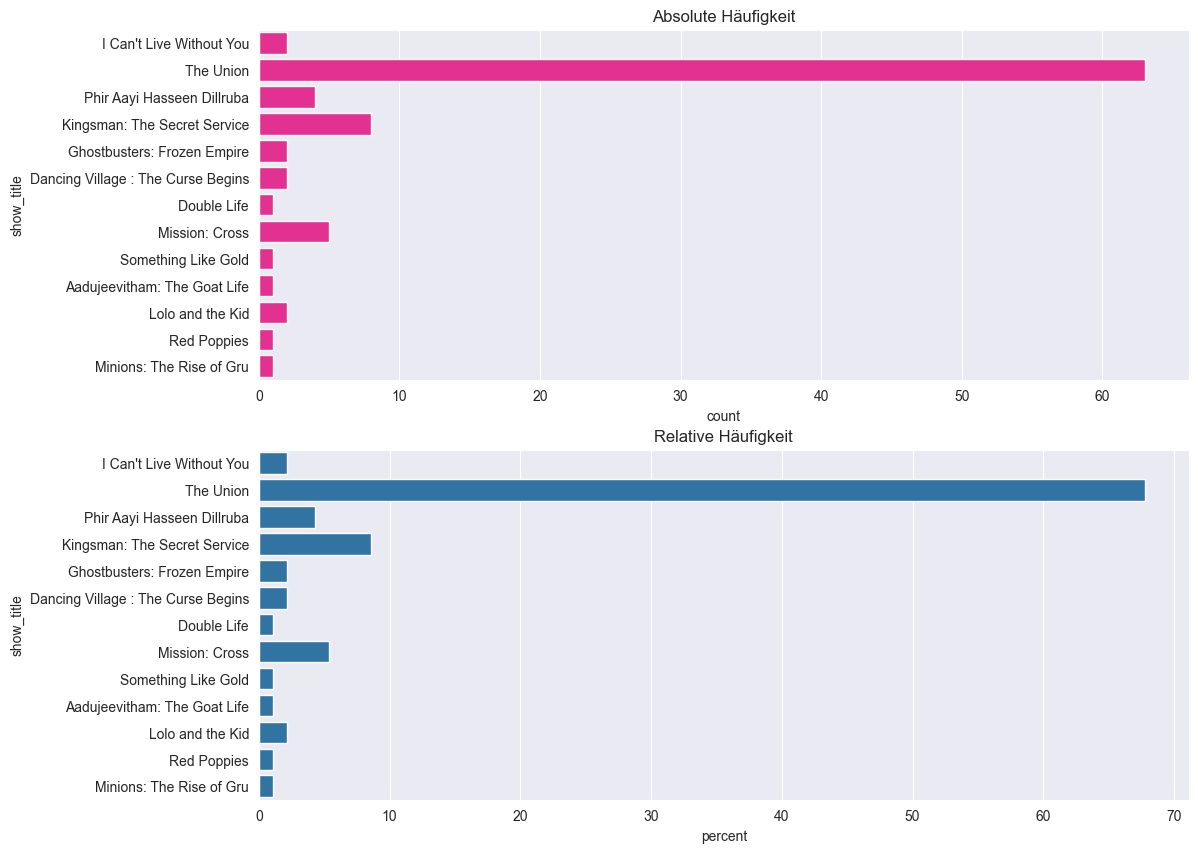

In [11]:
fig, axs = plt.subplots(nrows=2, ncols=1,figsize=(12,10))
sea.countplot(data=netflix_top, y='show_title', ax=axs[0], color='deeppink')
sea.countplot(data=netflix_top, y='show_title', stat='percent', ax=axs[1])
axs[0].set_title('Absolute Häufigkeit')
axs[1].set_title('Relative Häufigkeit')

### Visualisierung

Wir nehmen jetzt anstatt der Filme, die top-gerankten TV-Serien und erstellen entsprechende Häufigkeitsdiagramme.

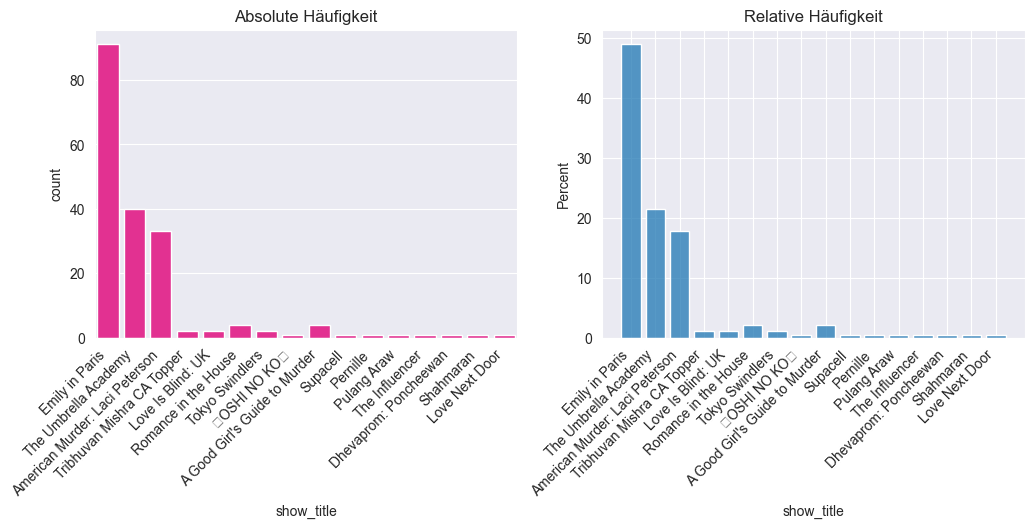

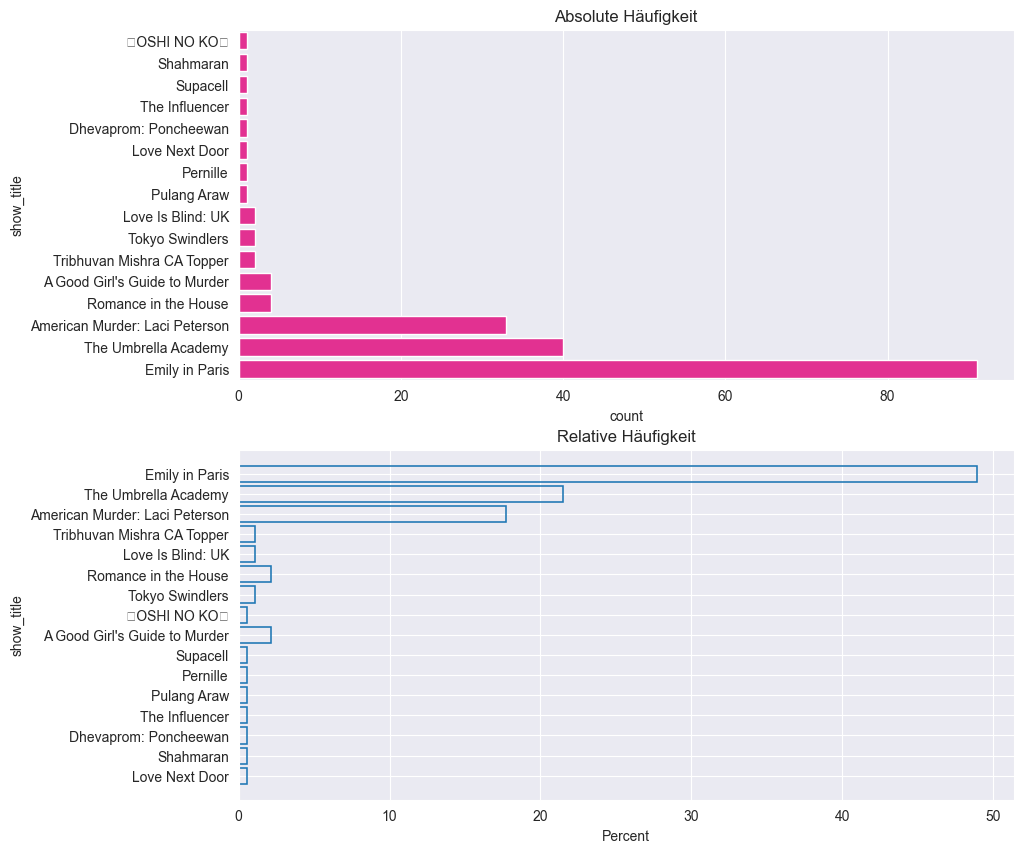

In [8]:
# tv-serien
netflix_toptv = netflix_lastweek[(netflix_lastweek['weekly_rank']<3) & (netflix_lastweek['category']=='TV')]

# Darstellung von Häufigkeitsdiagrammen mittels seaborn
fig, axs = plt.subplots(nrows=1, ncols= 2,figsize=(12,4))
sea.countplot(data=netflix_toptv, x='show_title', ax=axs[0], color='deeppink')
sea.histplot(data=netflix_toptv, x='show_title', stat='percent', ax=axs[1], shrink=0.8, discrete=True)
axs[0].set_title('Absolute Häufigkeit')
axs[1].set_title('Relative Häufigkeit')

# rotieren der x-Achsen Beschriftungen für verbesserte Lesbarkeit
for j in [0,1]:
    labels = axs[j].get_xticklabels()
    axs[j].set_xticks(labels=labels, ticks=np.arange(len(labels)), rotation=45.,\
                  horizontalalignment='right')
plt.show()

# countplot: https://seaborn.pydata.org/generated/seaborn.countplot.html
# histplot: https://seaborn.pydata.org/generated/seaborn.histplot.html

# bestimmung einer geordneten Liste der Ausprägungen
sorted_counts = netflix_toptv.value_counts('show_title')

# weitere Darstellungsformen
index = sorted_counts.sort_values().index.tolist()
fig, axs = plt.subplots(2,1,figsize=(10,10))
sea.countplot(data=netflix_toptv, y='show_title', ax=axs[0], color='deeppink', order=index)
sea.histplot(data=netflix_toptv, y='show_title', stat='percent', ax=axs[1], shrink=0.8, \
             discrete=True, fill=False)
axs[0].set_title('Absolute Häufigkeit')
axs[1].set_title('Relative Häufigkeit')

plt.show()

## Frage 

Wie sieht das relative und das absolute Häufigkeitsdiagramm der Ränge für den Film *Red Notice* über alle Länder und alle Wochen aus? Wie würde eine Darstellung einer entsprechenden kumulativen Häufigkeit der Ränge aussehen?

Text(0.5, 1.0, 'Kumulative Häufigkeit')

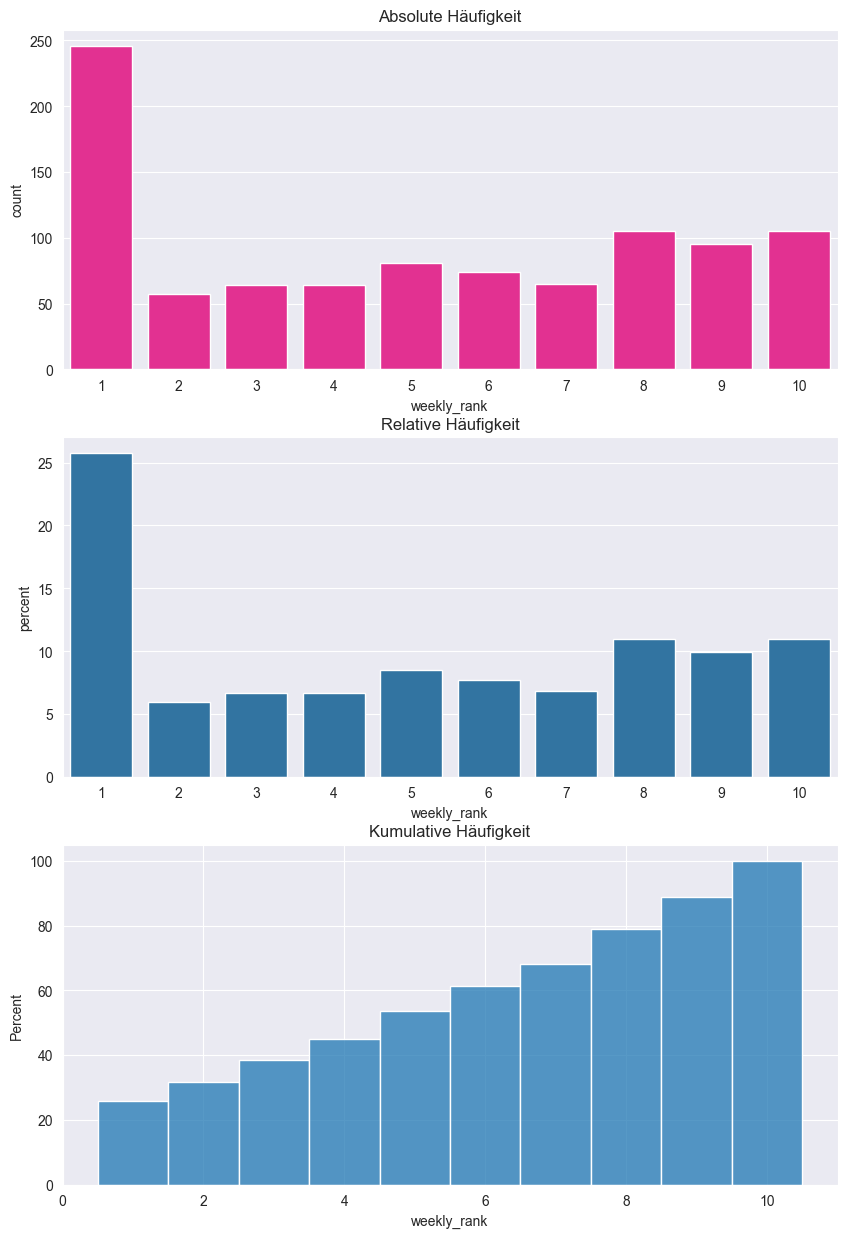

In [19]:
netflix_red_notice = netflix[netflix['show_title'] == 'Red Notice']
netflix_red_notice.head(10)

fig, axs = plt.subplots(nrows=3, ncols=1,figsize=(10,15))
sea.countplot(data=netflix_red_notice, x='weekly_rank', ax=axs[0], color='deeppink')
sea.countplot(data=netflix_red_notice, x='weekly_rank', stat='percent', ax=axs[1])
sea.histplot(data=netflix_red_notice, x='weekly_rank', cumulative=True, discrete=True, element="bars", stat='percent', ax=axs[2])
axs[0].set_title('Absolute Häufigkeit')
axs[1].set_title('Relative Häufigkeit')
axs[2].set_title('Kumulative Häufigkeit')

# Kumulative Häufigkeit -> z.B. Wie oft kommt Rang vier oder kleiner vor, wie oft kommt Rang 8 oder kleiner vor?
# Wie oft war dieser Film unter den Top 5?


### Quantitative Daten

In [32]:
# einlesen des Datensatzes
netflix2 = pd.read_excel('./data/all-weeks-global.xlsx')
netflix2_films = netflix2[netflix2['category']=='Films (English)']

## Frage

Benutze den Datensatz netflix2, um die relative und die kumulierte Häufigkeit für das Merkmal *runtime* darzustellen. 

<Axes: xlabel='runtime', ylabel='Proportion'>

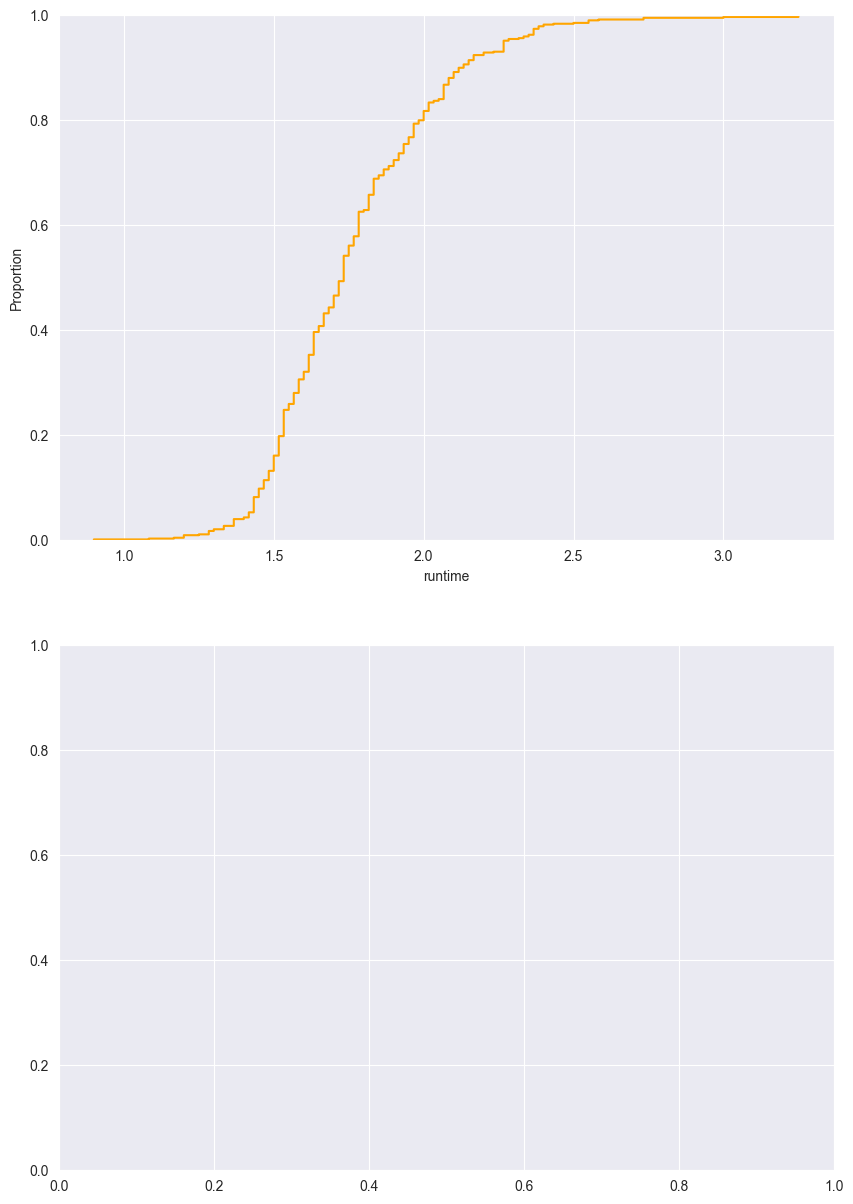

In [35]:
#                       Reihen      Spalten
fig, axs = plt.subplots(nrows=2, ncols=1,figsize=(10,15))
# sea.countplot(data=netflix2, x='runtime', ax=axs[0], color='deeppink')
# sea.countplot(data=netflix2, x='runtime', stat='percent', ax=axs[1])
sea.ecdfplot(data=netflix2_films, x='runtime', ax=axs[0], color='orange')

